# OncoMatch - Personalized Chemotherapy Drug Response Prediction in Cancer Treatments

**Course:** Machine Learning — PBL-I, PBL-II and PBL-III  
**Dataset:** GDSC2 fitted dose-response data  
**Methods:** Exploratory data analysis, regression/classification, K-Means clustering, an exploratory categorical HMM, and ensemble models for leakage-safe LN(IC50) prediction

## Table of contents
1. [Dataset loading](#1-dataset-loading)
2. [Dataset overview](#2-dataset-overview)
3. [Exploratory data analysis](#3-exploratory-data-analysis)
4. [Regression](#4-regression)
5. [Classification](#5-classification)
6. [Confusion matrix and specificity](#6-confusion-matrix-and-specificity)
7. [Regression model comparison](#7-regression-model-comparison)
8. [Categorical-feature regression](#8-categorical-feature-regression)
9. [K-Means clustering](#9-k-means-clustering)
10. [Hidden Markov Model](#10-hidden-markov-model)
11. [Comparative Performance Analysis and Interpretation](#11-comparative-performance-analysis-and-interpretation)
12. [PBL-III: Ensemble Model Development](#12-pbl-iii-ensemble-model-development)
13. [Production Packaging](#13-production-packaging)
14. [Final Summary](#14-final-summary)

## Reproducibility and scientific notes
- Run all cells **from top to bottom** in a fresh notebook runtime.
- Section 1 loads a local copy of the GDSC2 CSV if present (current folder, `data/`, `/content/`) and downloads it only as a fallback; the result is stored in `df`. Later sections reuse `df`; they do not download the dataset again.
- The PBL-I response-summary features (`AUC`, `Z_SCORE`, and `RMSE`) are related to the fitted response used as `LN_IC50`. Using them to predict `LN_IC50` can cause **target leakage**; describe those results as exploratory, not as validated pre-treatment clinical predictions.
- K-Means groups observed response records; it does not recommend treatment for an individual patient.
- The HMM is a method demonstration only. Drug IDs are used to impose a reproducible order, not biological time. Its transition matrix must not be interpreted as real biological progression.
- Section 12 (PBL-III) never uses `AUC`, `Z_SCORE` or `RMSE` as model inputs and evaluates on cell lines that were not used for training.
- No omics columns are present in the file; all results describe cell-line screens and are not clinical evidence.


### 1. Dataset loading

Load GDSC2 from a local copy of `GDSC2_fitted_dose_response_24Jul22.csv` if one is available; otherwise download it once from the Sanger source. The result is stored in `df`, and `load_gdsc()` is reused in Section 12.

In [1]:
import os
import pandas as pd

CSV_NAME = "GDSC2_fitted_dose_response_24Jul22.csv"
URL = "https://ftp.sanger.ac.uk/pub/project/cancerrxgene/releases/current_release/" + CSV_NAME
LOCAL_CANDIDATES = [CSV_NAME, "gdsc2_response.csv", os.path.join("data", CSV_NAME),
                    os.path.join("/content", CSV_NAME), os.path.join("/content/drive/MyDrive", CSV_NAME)]

def load_gdsc():
    """Load GDSC2 from a local copy if one exists; otherwise download it once from the Sanger site."""
    for path in LOCAL_CANDIDATES:
        if os.path.exists(path):
            print("Loading local file:", path)
            return pd.read_csv(path)
    import requests
    print("No local copy found; downloading from the Sanger site ...")
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/122.0 Safari/537.36"}
    response = requests.get(URL, headers=headers, timeout=60)
    response.raise_for_status()
    with open("gdsc2_response.csv", "wb") as f:
        f.write(response.content)
    return pd.read_csv("gdsc2_response.csv")

df = load_gdsc()
print("Shape:", df.shape)
df.head()

No local copy found; downloading from the Sanger site ...
Shape: (242036, 19)


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,COSMIC_ID,CELL_LINE_NAME,SANGER_MODEL_ID,TCGA_DESC,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,COMPANY_ID,WEBRELEASE,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,401,18945558,683667,PFSK-1,SIDM01132,MB,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-1.462148,0.930105,0.088999,0.432482
1,GDSC2,401,18945796,684052,A673,SIDM00848,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-4.869447,0.614932,0.111423,-1.420322
2,GDSC2,401,18946078,684057,ES5,SIDM00263,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.360684,0.790953,0.142754,-0.599894
3,GDSC2,401,18946335,684059,ES7,SIDM00269,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-5.045014,0.592624,0.135642,-1.515791
4,GDSC2,401,18946617,684062,EW-11,SIDM00203,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.741620,0.733992,0.128066,-0.807038


### 2. Dataset overview

Inspect data types, descriptive statistics, missing values, and the number of drugs and cancer types.

In [2]:
df.info()
print("\n", df.describe())
print("\nMissing values:\n", df.isnull().sum())
print("\nUnique drugs:", df['DRUG_NAME'].nunique())
print("Unique cancer types:", df['TCGA_DESC'].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242036 entries, 0 to 242035
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   DATASET          242036 non-null  object 
 1   NLME_RESULT_ID   242036 non-null  int64  
 2   NLME_CURVE_ID    242036 non-null  int64  
 3   COSMIC_ID        242036 non-null  int64  
 4   CELL_LINE_NAME   242036 non-null  object 
 5   SANGER_MODEL_ID  242036 non-null  object 
 6   TCGA_DESC        240969 non-null  object 
 7   DRUG_ID          242036 non-null  int64  
 8   DRUG_NAME        242036 non-null  object 
 9   PUTATIVE_TARGET  214881 non-null  object 
 10  PATHWAY_NAME     242036 non-null  object 
 11  COMPANY_ID       242036 non-null  int64  
 12  WEBRELEASE       242036 non-null  object 
 13  MIN_CONC         242036 non-null  float64
 14  MAX_CONC         242036 non-null  float64
 15  LN_IC50          242036 non-null  float64
 16  AUC              242036 non-null  floa

### 3. Exploratory Data Analysis (EDA)

Visualize LN(IC50), AUC by cancer type, feature correlations, and AUC versus LN(IC50).

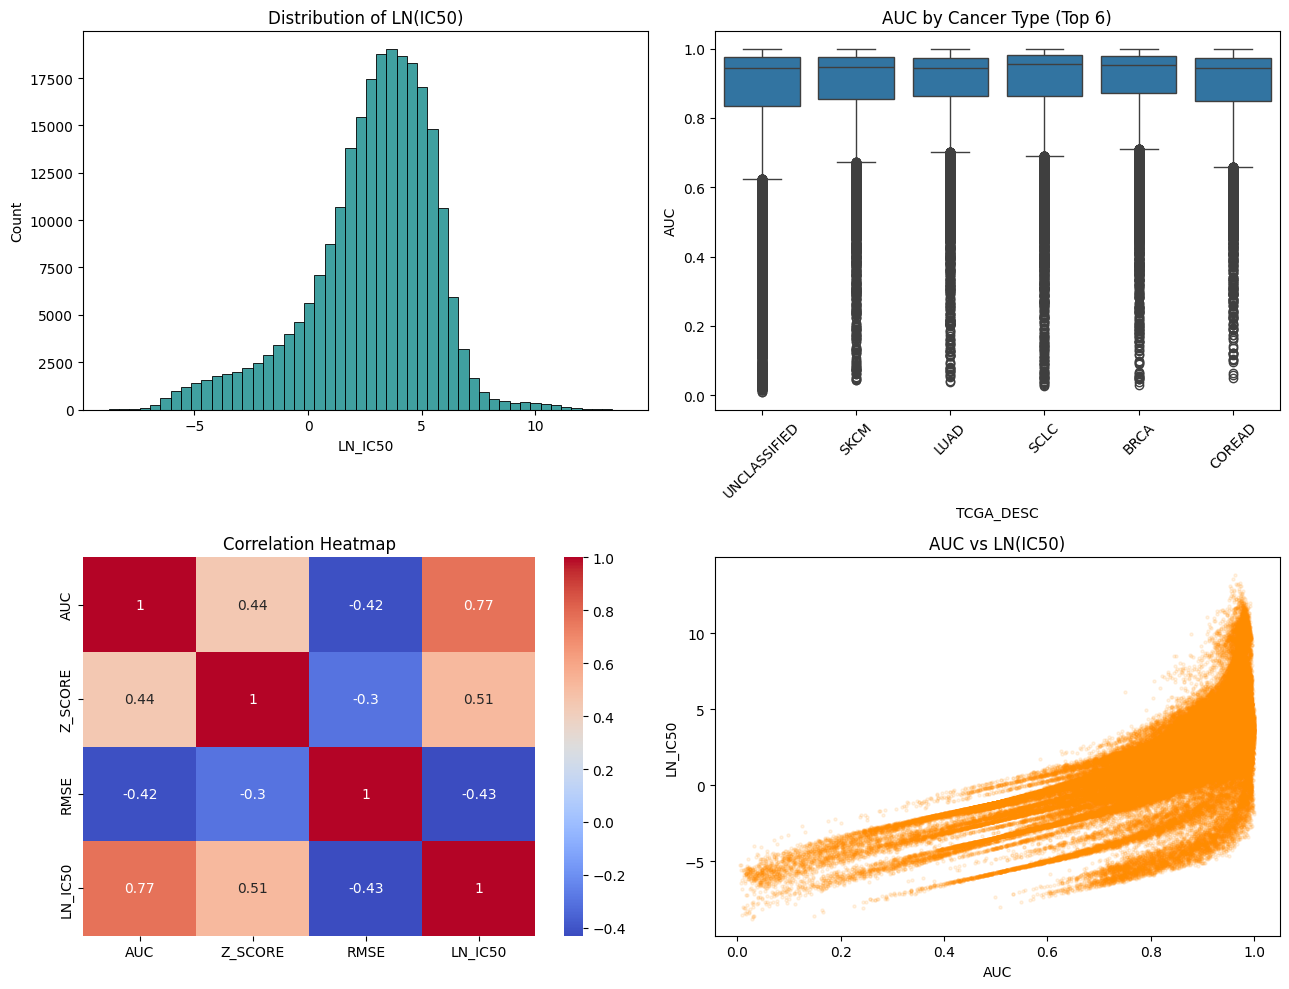

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.histplot(df['LN_IC50'].dropna(), bins=50, ax=axes[0,0], color='teal')
axes[0,0].set_title('Distribution of LN(IC50)')

top_cancers = df['TCGA_DESC'].value_counts().head(6).index
sns.boxplot(data=df[df['TCGA_DESC'].isin(top_cancers)], x='TCGA_DESC', y='AUC', ax=axes[0,1])
axes[0,1].set_title('AUC by Cancer Type (Top 6)')
axes[0,1].tick_params(axis='x', rotation=45)

corr = df[['AUC','Z_SCORE','RMSE','LN_IC50']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', ax=axes[1,0])
axes[1,0].set_title('Correlation Heatmap')

axes[1,1].scatter(df['AUC'], df['LN_IC50'], alpha=0.1, s=5, color='darkorange')
axes[1,1].set_xlabel('AUC'); axes[1,1].set_ylabel('LN_IC50')
axes[1,1].set_title('AUC vs LN(IC50)')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150)
plt.show()

### 4. Regression

Fit linear regression and report MAE, MSE, RMSE, and R² on a held-out test set.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

data = df[['AUC','Z_SCORE','RMSE','LN_IC50']].dropna()
X, y = data[['AUC','Z_SCORE','RMSE']], data['LN_IC50']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_train, y_train)
pred = lr.predict(X_test)

mae, mse = mean_absolute_error(y_test, pred), mean_squared_error(y_test, pred)
rmse, r2 = np.sqrt(mse), r2_score(y_test, pred)
print(f"MAE: {mae:.4f}\nMSE: {mse:.4f}\nRMSE: {rmse:.4f}\nR2: {r2:.4f}")

MAE: 1.1226
MSE: 2.7616
RMSE: 1.6618
R2: 0.6409


### 5. Classification

Create a median-based sensitivity label and compare Logistic Regression with SVM.

                     Accuracy  Precision    Recall        F1   AUC-ROC
Logistic Regression  0.845439   0.884782  0.793372  0.836588  0.911544
SVM                  0.845000   0.925187  0.747984  0.827202  0.911090


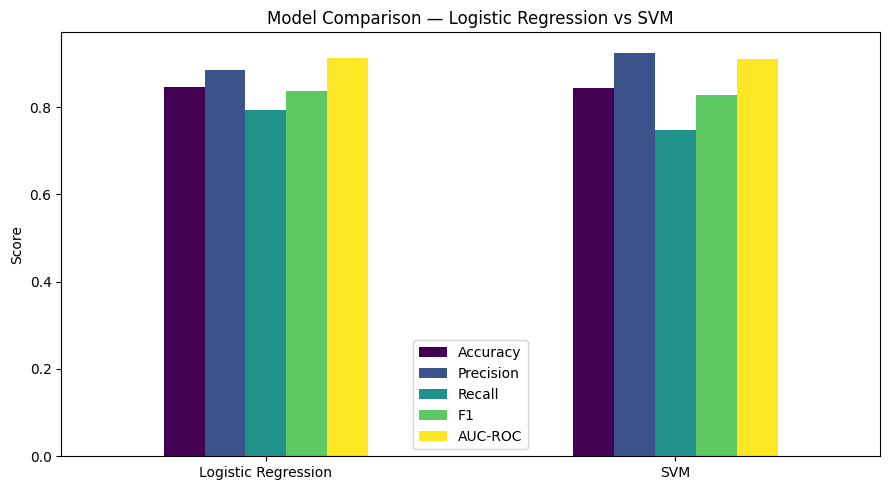

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

data = df[['AUC','Z_SCORE','RMSE','LN_IC50']].dropna()
data['Sensitivity'] = (data['LN_IC50'] < data['LN_IC50'].median()).astype(int)
X, y = data[['AUC','Z_SCORE','RMSE']], data['Sensitivity']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = {}
for name, model in [('Logistic Regression', LogisticRegression(max_iter=5000)),
                     ('SVM', SVC(kernel='linear', probability=True))]:
    sample_idx = X_train.sample(n=min(4000,len(X_train)), random_state=42).index if name=='SVM' else X_train.index
    model.fit(X_train.loc[sample_idx], y_train.loc[sample_idx])
    test_idx = X_test.sample(n=min(1000,len(X_test)), random_state=42).index if name=='SVM' else X_test.index
    pred = model.predict(X_test.loc[test_idx])
    proba = model.predict_proba(X_test.loc[test_idx])[:,1]
    results[name] = {
        'Accuracy': accuracy_score(y_test.loc[test_idx], pred),
        'Precision': precision_score(y_test.loc[test_idx], pred),
        'Recall': recall_score(y_test.loc[test_idx], pred),
        'F1': f1_score(y_test.loc[test_idx], pred),
        'AUC-ROC': roc_auc_score(y_test.loc[test_idx], proba)
    }

comp_df = pd.DataFrame(results).T
print(comp_df)

comp_df.plot(kind='bar', figsize=(9,5), colormap='viridis')
plt.title('Model Comparison — Logistic Regression vs SVM')
plt.ylabel('Score'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('model_comparison.png', dpi=150)
plt.show()

### 6. Confusion matrix and specificity

Evaluate the Logistic Regression classifier with a confusion matrix and specificity.

Specificity: 0.8972


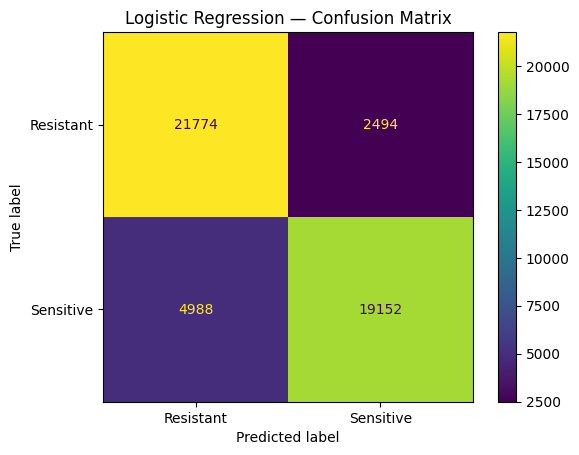

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

logreg = LogisticRegression(max_iter=5000).fit(X_train, y_train)
pred_lr = logreg.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred_lr).ravel()
print("Specificity:", round(tn/(tn+fp), 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=['Resistant','Sensitive'])
plt.title('Logistic Regression — Confusion Matrix'); plt.show()

### 7. Regression model comparison

Compare Linear Regression, Ridge, and Random Forest using MAE, RMSE, and R².

                        MAE      RMSE        R2
Linear Regression  1.122568  1.661800  0.640941
Ridge              1.122544  1.661804  0.640939
Random Forest      1.061925  1.566483  0.680949


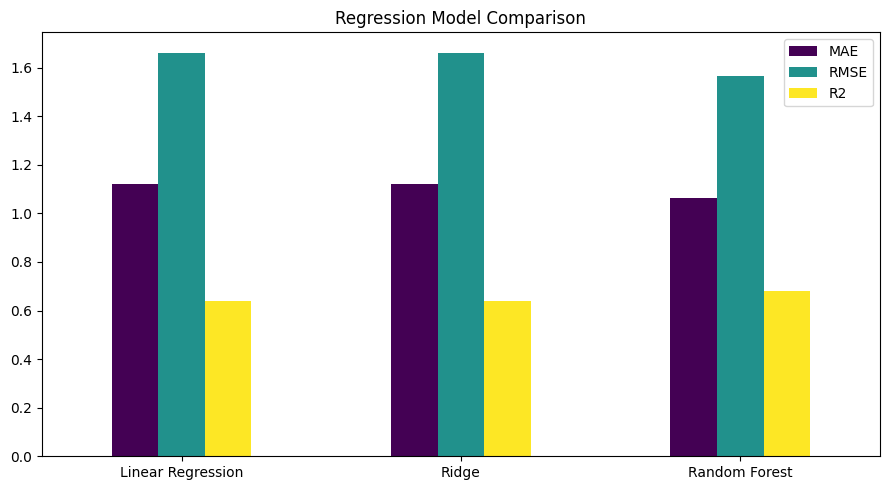

In [7]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

reg = df[['AUC','Z_SCORE','RMSE','LN_IC50']].dropna()
Xr, yr = reg[['AUC','Z_SCORE','RMSE']], reg['LN_IC50']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
rf_idx = Xr_tr.sample(n=min(20000, len(Xr_tr)), random_state=42).index

rows = {}
for name, m, idx in [('Linear Regression', LinearRegression(), Xr_tr.index),
                     ('Ridge', Ridge(alpha=1.0), Xr_tr.index),
                     ('Random Forest', RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42), rf_idx)]:
    m.fit(Xr_tr.loc[idx], yr_tr.loc[idx]); p_ = m.predict(Xr_te)
    rows[name] = {'MAE': mean_absolute_error(yr_te, p_), 'RMSE': np.sqrt(mean_squared_error(yr_te, p_)), 'R2': r2_score(yr_te, p_)}
reg_df = pd.DataFrame(rows).T
print(reg_df)
reg_df.plot(kind='bar', figsize=(9,5), colormap='viridis'); plt.title('Regression Model Comparison')
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('regression_comparison.png', dpi=150); plt.show()

### 8. Categorical-feature regression

Use one-hot encoded drug/cancer/pathway categories in a Ridge regression pipeline.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

cat = df[['DRUG_NAME','TCGA_DESC','PATHWAY_NAME','LN_IC50']].copy()
cat['TCGA_DESC'] = cat['TCGA_DESC'].fillna('UNKNOWN')
Xc, yc = cat[['DRUG_NAME','TCGA_DESC','PATHWAY_NAME']], cat['LN_IC50']
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=42)

pipe = make_pipeline(ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), list(Xc.columns))]), Ridge(alpha=1.0))
pipe.fit(Xc_tr, yc_tr); pc = pipe.predict(Xc_te)
print(f"MAE: {mean_absolute_error(yc_te, pc):.4f}  RMSE: {np.sqrt(mean_squared_error(yc_te, pc)):.4f}  R2: {r2_score(yc_te, pc):.4f}")

MAE: 1.0507  RMSE: 1.4062  R2: 0.7429


---

# 9. K-Means Clustering

This section reuses the `df` dataframe loaded in PBL-I. It only downloads the dataset if a compatible dataframe is not present. Clustering uses four fitted response-summary features and is therefore an exploratory grouping of observed drug-response records, not a pre-treatment prediction model.

### 9.1. Check the dataframe and import tools

Reuse `df`, confirm the required columns exist, and import the K-Means tools.

In [9]:
# Import only the tools needed for K-Means; reuse `df` from the first cell.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

required_columns = ["CELL_LINE_NAME", "DRUG_NAME", "LN_IC50", "AUC", "Z_SCORE", "RMSE"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        "The already-loaded dataframe is missing required columns: "
        + ", ".join(missing_columns)
    )

print("Reusing the GDSC2 dataframe loaded in Section 1.")
print("Dataset shape:", df.shape)
print("Unique cell lines:", df["CELL_LINE_NAME"].nunique())
print("Unique drugs:", df["DRUG_NAME"].nunique())
display(df.head())


Reusing the GDSC2 dataframe loaded in Section 1.
Dataset shape: (242036, 19)
Unique cell lines: 969
Unique drugs: 286


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,COSMIC_ID,CELL_LINE_NAME,SANGER_MODEL_ID,TCGA_DESC,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,COMPANY_ID,WEBRELEASE,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,401,18945558,683667,PFSK-1,SIDM01132,MB,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-1.462148,0.930105,0.088999,0.432482
1,GDSC2,401,18945796,684052,A673,SIDM00848,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-4.869447,0.614932,0.111423,-1.420322
2,GDSC2,401,18946078,684057,ES5,SIDM00263,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.360684,0.790953,0.142754,-0.599894
3,GDSC2,401,18946335,684059,ES7,SIDM00269,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-5.045014,0.592624,0.135642,-1.515791
4,GDSC2,401,18946617,684062,EW-11,SIDM00203,UNCLASSIFIED,1003,Camptothecin,TOP1,DNA replication,1046,Y,0.0001,0.1,-3.741620,0.733992,0.128066,-0.807038


### 9.2. Prepare K-Means features

Select the four response-summary features, drop missing or infinite values, standardize them, and report rows retained.

In [10]:
features = ['LN_IC50', 'AUC', 'Z_SCORE', 'RMSE']
data = df[features].replace([np.inf, -np.inf], np.nan).dropna().copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)
print('Rows used:', len(data))
print('Rows removed due to missing/invalid selected values:', len(df) - len(data))

Rows used: 242036
Rows removed due to missing/invalid selected values: 0


### 9.3. Select the number of clusters

Compare candidate cluster counts (k = 2 to 6) on a reproducible sample using silhouette, Davies–Bouldin, and Calinski–Harabasz scores.

,k,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,0.4149,1.0580,7086.6230
1,3,0.3077,1.1662,6021.8137
2,4,0.2548,1.2280,5314.4316
3,5,0.2544,1.2973,4721.0389
4,6,0.2442,1.2931,4387.0863


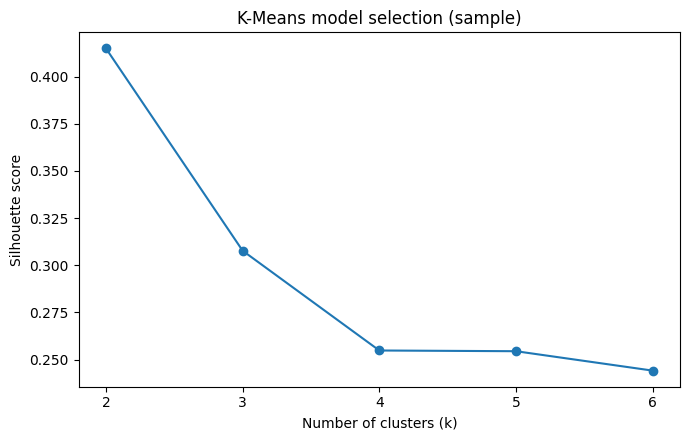

In [11]:
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_scaled), size=min(10000, len(X_scaled)), replace=False)
X_sample = X_scaled[sample_idx]
score_rows = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = model.fit_predict(X_sample)
    score_rows.append({
        'k': k,
        'Silhouette': silhouette_score(X_sample, sample_labels),
        'Davies-Bouldin': davies_bouldin_score(X_sample, sample_labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_sample, sample_labels)
    })
scores = pd.DataFrame(score_rows)
display(scores.round(4))
plt.figure(figsize=(7, 4.5))
plt.plot(scores['k'], scores['Silhouette'], marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('K-Means model selection (sample)')
plt.xticks(range(2, 7))
plt.tight_layout()
plt.show()

### 9.4. Fit and summarize K-Means

Fit the two-cluster model on all retained records and summarize cluster counts, means, and medians.

In [12]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
clustered = data.copy()
clustered['Cluster'] = labels
print('Cluster counts:')
display(clustered['Cluster'].value_counts().sort_index().rename('Records').to_frame())
print('Mean values by cluster:')
display(clustered.groupby('Cluster')[features].mean().round(4))
print('Median values by cluster:')
display(clustered.groupby('Cluster')[features].median().round(4))

Cluster counts:


,Records
Cluster,
0,168604
1,73432


Mean values by cluster:


,LN_IC50,AUC,Z_SCORE,RMSE
Cluster,,,,
0,4.1322,0.9514,0.3443,0.0660
1,-0.1474,0.7249,-0.7905,0.1211


Median values by cluster:


,LN_IC50,AUC,Z_SCORE,RMSE
Cluster,,,,
0,4.1244,0.9660,0.3306,0.0632
1,0.4550,0.7687,-0.7642,0.1162


### 9.5. Visualize clusters

Plot a reproducible sample of records by AUC and LN(IC50), colored by cluster.

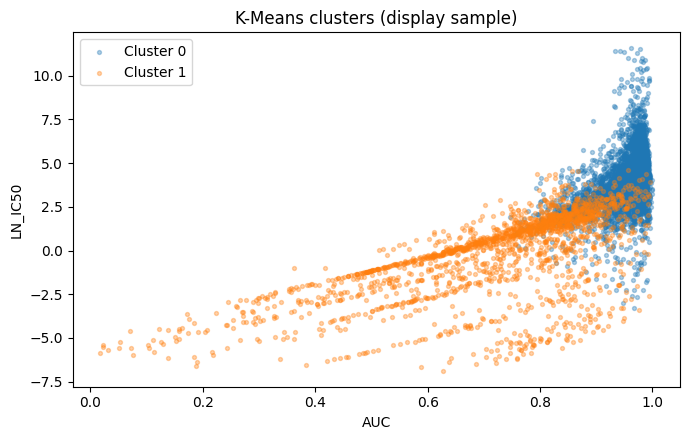

In [13]:
plot_sample = clustered.sample(n=min(6000, len(clustered)), random_state=42)
plt.figure(figsize=(7, 4.5))
for cluster_id in sorted(plot_sample['Cluster'].unique()):
    subset = plot_sample[plot_sample['Cluster'] == cluster_id]
    plt.scatter(subset['AUC'], subset['LN_IC50'], s=8, alpha=0.35, label=f'Cluster {cluster_id}')
plt.xlabel('AUC')
plt.ylabel('LN_IC50')
plt.title('K-Means clusters (display sample)')
plt.legend()
plt.tight_layout()
plt.show()

# 10. Hidden Markov Model (HMM)

## What this experiment does

**Important limitation:** GDSC2 fitted drug-response records are not a natural time series. The code orders drugs by `DRUG_ID` only to create reproducible sequences. Therefore, learned transitions describe this artificial ordering and must not be interpreted as biological progression or real temporal transitions.

This exploratory demonstration:
1. Groups fitted response records by cancer cell line and drug ID.
2. Converts `LN_IC50` into three dataset-relative observation categories using tertile cut-offs.
3. Sorts each cell line's observations by numeric `DRUG_ID` to form a reproducible sequence.
4. Fits a categorical HMM with three hidden states and prints initial, transition and emission probabilities.
5. Decodes the most likely hidden-state sequence and summarizes the observed `LN_IC50` values by decoded state.

**Scientific limitation:** different drugs are not time steps, and `DRUG_ID` order is not a biological sequence. Thus the learned transition matrix is conditional on this constructed ordering and should be presented as a method demonstration only. Hidden states are arbitrary statistical states, not validated sensitive/resistant classes.

### 10.1. Install HMM dependency

Install the HMM package in the current notebook runtime.

In [14]:
%pip install -q "hmmlearn>=0.3.0"

### 10.2. Prepare HMM records

Reuse `df` loaded in Section 1 and clean only the columns needed for the HMM.

In [15]:
# Reuse the dataframe loaded in Section 1; do not download the dataset again.
import numpy as np

required_hmm_columns = {"CELL_LINE_NAME", "DRUG_ID", "LN_IC50"}
missing = required_hmm_columns - set(df.columns)
if missing:
    raise ValueError(
        "The already-loaded dataframe is missing HMM columns: "
        + ", ".join(sorted(missing))
    )

hmm_df = df[["CELL_LINE_NAME", "DRUG_ID", "LN_IC50"]].copy()
hmm_df["LN_IC50"] = pd.to_numeric(hmm_df["LN_IC50"], errors="coerce")
hmm_df["DRUG_ID"] = pd.to_numeric(hmm_df["DRUG_ID"], errors="coerce")
hmm_df = hmm_df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["CELL_LINE_NAME", "DRUG_ID", "LN_IC50"]
)

print("Reusing the GDSC2 dataframe loaded in Section 1.")
print("Usable HMM records:", len(hmm_df))
print("Unique cell lines:", hmm_df["CELL_LINE_NAME"].nunique())
print("Unique drug IDs:", hmm_df["DRUG_ID"].nunique())
display(hmm_df.head())


Reusing the GDSC2 dataframe loaded in Section 1.
Usable HMM records: 242036
Unique cell lines: 969
Unique drug IDs: 295


,CELL_LINE_NAME,DRUG_ID,LN_IC50
0,PFSK-1,1003,-1.462148
1,A673,1003,-4.869447
2,ES5,1003,-3.360684
3,ES7,1003,-5.045014
4,EW-11,1003,-3.741620


### 10.3. Create observation symbols

Aggregate cell-line/drug pairs and convert LN(IC50) into three dataset-relative categories.

In [16]:
# Use one median fitted LN(IC50) value for each cell-line/drug pair.
pairs = (
    hmm_df.groupby(["CELL_LINE_NAME", "DRUG_ID"], as_index=False)["LN_IC50"]
    .median()
)

# Dataset-relative tertiles produce three discrete observation symbols.
q1, q2 = pairs["LN_IC50"].quantile([1/3, 2/3]).to_numpy()

def categorize_response(value):
    if value <= q1:
        return 0  # lower LN(IC50) relative to this dataset
    elif value <= q2:
        return 1  # middle category
    return 2      # higher LN(IC50) relative to this dataset

pairs["OBSERVATION"] = pairs["LN_IC50"].apply(categorize_response).astype(int)

print(f"Lower/middle boundary (tertile 1): {q1:.4f}")
print(f"Middle/higher boundary (tertile 2): {q2:.4f}")
print("\nObservation category counts:")
print(pairs["OBSERVATION"].value_counts().sort_index().rename(
    index={0: "0 = lower LN_IC50", 1: "1 = middle", 2: "2 = higher LN_IC50"}
))
display(pairs.head())

Lower/middle boundary (tertile 1): 2.1929
Middle/higher boundary (tertile 2): 4.2193

Observation category counts:
OBSERVATION
0 = lower LN_IC50     80679
1 = middle            80678
2 = higher LN_IC50    80679
Name: count, dtype: int64


,CELL_LINE_NAME,DRUG_ID,LN_IC50,OBSERVATION
0,22RV1,1003,-2.902460,0
1,22RV1,1004,-4.384381,0
2,22RV1,1005,3.372862,1
3,22RV1,1006,4.189364,1
4,22RV1,1007,-3.693711,0


### 10.4. Construct observation sequences

Create one sequence per cell line, ordered by DRUG_ID as an artificial reproducible convention.

In [17]:
# Construct one sequence per cell line, ordered by DRUG_ID.
# This is a reproducible convention, NOT a biological time sequence.
pairs = pairs.sort_values(
    ["CELL_LINE_NAME", "DRUG_ID"]
).reset_index(drop=True)

sequences = []
sequence_names = []

for cell_line, group in pairs.groupby("CELL_LINE_NAME", sort=True):
    observations = group["OBSERVATION"].to_numpy(dtype=int)
    if len(observations) >= 3:
        sequences.append(observations)
        sequence_names.append(cell_line)

if len(sequences) < 2:
    raise ValueError(
        "Too few cell-line sequences with at least 3 observations to fit the HMM."
    )

lengths = [len(seq) for seq in sequences]
# Keep only rows represented in the concatenated sequences so decoded labels align.
pairs = pairs[pairs["CELL_LINE_NAME"].isin(sequence_names)].copy()
pairs = pairs.sort_values(["CELL_LINE_NAME", "DRUG_ID"]).reset_index(drop=True)
X_hmm = np.concatenate(sequences).reshape(-1, 1)

print("Number of cell-line sequences:", len(sequences))
print("Total discrete observations:", len(X_hmm))
print("First sequence cell line:", sequence_names[0])
print("First sequence length:", lengths[0])
print("First 15 observation symbols:", sequences[0][:15].tolist())

Number of cell-line sequences: 969
Total discrete observations: 242036
First sequence cell line: 22RV1
First sequence length: 280
First 15 observation symbols: [0, 0, 1, 1, 0, 0, 2, 2, 0, 2, 1, 0, 2, 2, 1]


### 10.5. Fit HMM and inspect probabilities

Fit a three-state categorical HMM and display initial, transition, and emission probabilities.

In [18]:
from hmmlearn.hmm import CategoricalHMM

# Three hidden states and three possible discrete observation symbols.
hmm_model = CategoricalHMM(
    n_components=3,
    n_features=3,
    n_iter=100,
    tol=1e-3,
    random_state=42,
    verbose=False
)

hmm_model.fit(X_hmm, lengths)

print("HMM fitting finished.")
print("Converged:", hmm_model.monitor_.converged)
print("Iterations:", hmm_model.monitor_.iter)
print("Log-likelihood on fitted sequences:", round(hmm_model.score(X_hmm, lengths), 4))

print("\nInitial-state probabilities:")
print(np.round(hmm_model.startprob_, 4))

print("\nTransition probabilities (rows=current state, columns=next state):")
print(np.round(hmm_model.transmat_, 4))

print("\nEmission probabilities (columns: lower, middle, higher LN(IC50) categories):")
print(np.round(hmm_model.emissionprob_, 4))

HMM fitting finished.
Converged: True
Iterations: 100
Log-likelihood on fitted sequences: -254147.5986

Initial-state probabilities:
[1. 0. 0.]

Transition probabilities (rows=current state, columns=next state):
[[0.001  0.999  0.    ]
 [0.9035 0.0089 0.0876]
 [0.0264 0.0039 0.9697]]

Emission probabilities (columns: lower, middle, higher LN(IC50) categories):
[[0.4885 0.412  0.0995]
 [0.5099 0.3475 0.1426]
 [0.196  0.2951 0.5088]]


### 10.6. Decode hidden states

Decode the most likely hidden states and summarize LN(IC50) for each state.

In [19]:
# Viterbi decoding: most likely hidden state for each observation in each sequence.
hidden_states = hmm_model.predict(X_hmm, lengths)

decoded = pairs.copy()
decoded["HIDDEN_STATE"] = hidden_states

print("Decoded observations:", len(hidden_states))
print("\nHidden-state counts:")
print(decoded["HIDDEN_STATE"].value_counts().sort_index())

state_summary = (
    decoded.groupby("HIDDEN_STATE")
    .agg(
        Records=("LN_IC50", "size"),
        Mean_LN_IC50=("LN_IC50", "mean"),
        Median_LN_IC50=("LN_IC50", "median"),
        Mean_Observation_Category=("OBSERVATION", "mean")
    )
    .round(4)
)

print("\nDescriptive summary by decoded hidden state:")
display(state_summary)

Decoded observations: 242036

Hidden-state counts:
HIDDEN_STATE
0     52200
1     52136
2    137700
Name: count, dtype: int64

Descriptive summary by decoded hidden state:


,Records,Mean_LN_IC50,Median_LN_IC50,Mean_Observation_Category
HIDDEN_STATE,,,,
0,52200,1.6464,2.2567,0.6093
1,52136,1.6285,2.1425,0.6365
2,137700,3.7402,4.1858,1.2857


### 10.7. Plot transition matrix

Visualize the learned transition probabilities.

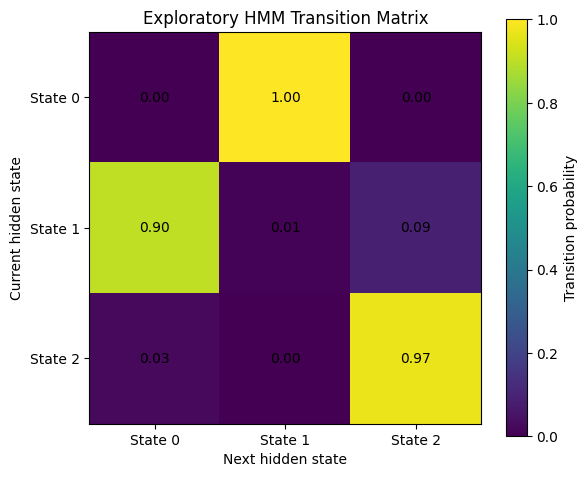

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(hmm_model.transmat_, vmin=0, vmax=1, aspect="equal")
plt.colorbar(label="Transition probability")
plt.xticks([0, 1, 2], ["State 0", "State 1", "State 2"])
plt.yticks([0, 1, 2], ["State 0", "State 1", "State 2"])
plt.xlabel("Next hidden state")
plt.ylabel("Current hidden state")
plt.title("Exploratory HMM Transition Matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{hmm_model.transmat_[i, j]:.2f}",
                 ha="center", va="center")

plt.tight_layout()
plt.show()

### 10.8. Export HMM outputs

Save decoded states and the state, transition, and emission summaries as CSV files.

In [21]:
# Export actual results produced by this run.
decoded.to_csv("OncoMatch_HMM_Decoded_States.csv", index=False)
state_summary.to_csv("OncoMatch_HMM_State_Summary.csv")

transition_df = pd.DataFrame(
    hmm_model.transmat_,
    index=["State 0", "State 1", "State 2"],
    columns=["State 0", "State 1", "State 2"]
)
transition_df.to_csv("OncoMatch_HMM_Transition_Matrix.csv")

emission_df = pd.DataFrame(
    hmm_model.emissionprob_,
    index=["State 0", "State 1", "State 2"],
    columns=["Lower LN_IC50 category", "Middle category", "Higher LN_IC50 category"]
)
emission_df.to_csv("OncoMatch_HMM_Emission_Matrix.csv")

print("Saved actual outputs:")
print("- OncoMatch_HMM_Decoded_States.csv")
print("- OncoMatch_HMM_State_Summary.csv")
print("- OncoMatch_HMM_Transition_Matrix.csv")
print("- OncoMatch_HMM_Emission_Matrix.csv")

Saved actual outputs:
- OncoMatch_HMM_Decoded_States.csv
- OncoMatch_HMM_State_Summary.csv
- OncoMatch_HMM_Transition_Matrix.csv
- OncoMatch_HMM_Emission_Matrix.csv


---
# 11. Comparative Performance Analysis and Interpretation

K-Means and HMM solve different tasks, so their numerical scores are **not directly comparable**. K-Means groups records using feature-space distances; its internal clustering metrics assess cluster structure. The HMM estimates hidden states for the artificially ordered response-category sequences; its log-likelihood measures fit to those sequences, not clinical prediction accuracy.

The HMM sequence order is by `DRUG_ID`, not time. Treat its state transitions as exploratory patterns under this ordering only. Do not claim real biological transitions, patient-level treatment recommendations, or clinical validation.


In [22]:
# Summarize actual metrics generated by the preceding model cells.
comparison_rows = []

if 'scores' in globals() and not scores.empty:
    best_row = scores.loc[scores['Silhouette'].idxmax()]
    comparison_rows.append({
        'Model': 'K-Means',
        'Objective': 'Cluster response records by scaled fitted-response features',
        'Reported metric': 'Silhouette (sample; higher is generally better)',
        'Value': float(best_row['Silhouette']),
        'Interpretation / limitation': f"Best tested k={int(best_row['k'])}; internal cluster metric, not biological validation."
    })

if 'hmm_model' in globals() and 'X_hmm' in globals() and 'lengths' in globals():
    comparison_rows.append({
        'Model': 'Categorical HMM',
        'Objective': 'Estimate hidden states for discretized response sequences',
        'Reported metric': 'Training log-likelihood (higher indicates better fit for the same data/model setup)',
        'Value': float(hmm_model.score(X_hmm, lengths)),
        'Interpretation / limitation': 'Fit to DRUG_ID-ordered artificial sequences; not comparable to silhouette and not a clinical accuracy score.'
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
comparison_df.to_csv('OncoMatch_PBL2_Model_Comparison.csv', index=False)
print('Saved: OncoMatch_PBL2_Model_Comparison.csv')


,Model,Objective,Reported metric,Value,Interpretation / limitation
0,K-Means,Cluster response records by scaled fitted-resp...,Silhouette (sample; higher is generally better),0.414920,"Best tested k=2; internal cluster metric, not ..."
1,Categorical HMM,Estimate hidden states for discretized respons...,Training log-likelihood (higher indicates bett...,-254147.598578,Fit to DRUG_ID-ordered artificial sequences; n...


Saved: OncoMatch_PBL2_Model_Comparison.csv


---
# 12. PBL-III: Ensemble Model Development

## Problem statement
Predict the fitted **LN(IC50)** of a (cell line, drug) pair in GDSC2 using only information that would be known **before** the assay: drug identity, putative target, pathway, tissue (`TCGA_DESC`) and the tested concentration range.

## Protocol (fixed before any model was fitted)
- **Forbidden inputs:** `AUC`, `Z_SCORE` and `RMSE` are outputs of the same curve fit as `LN_IC50` and are **never used as inputs** in this section (they caused the leakage noted in PBL-I).
- **Grouped split:** `GroupShuffleSplit` by `COSMIC_ID` (80:20, seed 42), so no cell line appears in both train and test.
- **Scenario A:** ordinal-coded categories (`DRUG_ID`, `PUTATIVE_TARGET`, `PATHWAY_NAME`, `TCGA_DESC`) + `LOG_MAX` + `LOG_RANGE`.
- **Scenario B:** Scenario A + smoothed (k = 10, shrunk toward the global training mean) target encodings (DRUG, DRUG x TISSUE, TISSUE) fitted on training data only, computed **out-of-fold** (GroupKFold, 5 folds) for training rows.
- **Scenario C:** Scenario B + a 15-drug "probe" fingerprint of the cell line (needs the 15 probe assays on a new cell line).
- **Metrics:** test MAE, RMSE and R2 (lower MAE/RMSE and higher R2 are better).

The file contains no omics columns, so these models describe drug and tissue patterns in cell-line screens. They are not clinical evidence.

In [23]:
# 12.1 Setup and data audit
import os, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, roc_auc_score

SEED = 42
N_JOBS = -1
TARGET = "LN_IC50"
FORBIDDEN_INPUTS = ["AUC", "Z_SCORE", "RMSE"]

g = load_gdsc().reset_index(drop=True)      # fresh copy, independent of earlier sections
print("Rows x columns        :", g.shape)
print("Cell lines (COSMIC_ID):", g["COSMIC_ID"].nunique())
print("DRUG_IDs / drug names :", g["DRUG_ID"].nunique(), "/", g["DRUG_NAME"].nunique())
print("TCGA_DESC / pathways  :", g["TCGA_DESC"].nunique(), "/", g["PATHWAY_NAME"].nunique())
omics_like = [c for c in g.columns if c.upper().startswith(("GENE", "EXPR", "MUT", "CNV"))]
print("Omics-like columns    :", omics_like if omics_like else "none")
print("Missing values (columns with any):")
print(g.isna().sum()[g.isna().sum() > 0].to_string())
assert g.shape == (242036, 19) and g["COSMIC_ID"].nunique() == 969
assert (g["MAX_CONC"] > 0).all() and (g["MIN_CONC"] > 0).all()

Loading local file: gdsc2_response.csv
Rows x columns        : (242036, 19)
Cell lines (COSMIC_ID): 969
DRUG_IDs / drug names : 295 / 286
TCGA_DESC / pathways  : 32 / 24
Omics-like columns    : none
Missing values (columns with any):
TCGA_DESC           1067
PUTATIVE_TARGET    27155


In [24]:
# 12.2 Cell-line-grouped 80:20 split (no cell line in both sets)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(g, groups=g["COSMIC_ID"]))
train = g.iloc[tr_idx].reset_index(drop=True)
test = g.iloc[te_idx].reset_index(drop=True)
overlap = set(train["COSMIC_ID"]) & set(test["COSMIC_ID"])
print(f"Train: {len(train):,} rows, {train['COSMIC_ID'].nunique()} cell lines")
print(f"Test : {len(test):,} rows, {test['COSMIC_ID'].nunique()} cell lines")
print("Cell-line overlap:", len(overlap))
assert len(overlap) == 0
y_train, y_test = train[TARGET].values, test[TARGET].values
train_median = float(np.median(y_train))
print(f"Training median LN_IC50 (used later as sensitivity threshold): {train_median:.3f}")

Train: 193,591 rows, 775 cell lines
Test : 48,445 rows, 194 cell lines
Cell-line overlap: 0
Training median LN_IC50 (used later as sensitivity threshold): 3.246


In [25]:
# 12.3 Leakage-safe featurizer (written to a module so the saved model can be loaded in any process)
import sys
from pathlib import Path
K_SMOOTH = 10
Path('oncomatch_features.py').write_text('"""Leakage-safe feature builder for OncoMatch."""\nimport numpy as np, pandas as pd\nfrom sklearn.model_selection import GroupKFold\nfrom sklearn.preprocessing import OrdinalEncoder\n\nclass DrugResponseFeaturizer:\n    """Ordinal categories + log10 concentration features + smoothed target encodings.\n    Statistics come from training rows only; training rows get out-of-fold (cell-line-grouped) encodings."""\n    CATS = ["DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME", "TCGA_DESC"]\n    KEYS = [(["DRUG_ID"], "DRUG_TE"), (["DRUG_ID", "TCGA_DESC"], "DRUG_TISSUE_TE"), (["TCGA_DESC"], "TISSUE_TE")]\n    def __init__(self, smoothing=10, n_folds=5, target_encoding=True):\n        self.smoothing, self.n_folds, self.target_encoding = smoothing, n_folds, target_encoding\n    @staticmethod\n    def _clean(d):\n        d = d.copy()\n        d["PUTATIVE_TARGET"] = d["PUTATIVE_TARGET"].fillna("UNKNOWN"); d["TCGA_DESC"] = d["TCGA_DESC"].fillna("UNKNOWN")\n        return d\n    def _stats(self, d):\n        return {n: d.groupby(k)["LN_IC50"].agg(["sum", "count"]) for k, n in self.KEYS}\n    def _encode(self, stats, d, prior):\n        out = pd.DataFrame(index=d.index)\n        for k, n in self.KEYS:\n            m = d[k].merge(stats[n], left_on=k, right_index=True, how="left")\n            out[n] = (m["sum"].fillna(0).values + self.smoothing * prior) / (m["count"].fillna(0).values + self.smoothing)\n        return out\n    def _base(self, d):\n        X = pd.DataFrame(self.enc_.transform(d[self.CATS].astype(str)), columns=self.CATS, index=d.index)\n        X["LOG_MAX"] = np.log10(d["MAX_CONC"]); X["LOG_RANGE"] = np.log10(d["MAX_CONC"] / d["MIN_CONC"])\n        return X\n    def fit_transform(self, d, groups):\n        d = self._clean(d)\n        self.enc_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(d[self.CATS].astype(str))\n        self.prior_ = d["LN_IC50"].mean(); self.stats_ = self._stats(d)\n        X = self._base(d)\n        if self.target_encoding:\n            oof = pd.DataFrame(index=d.index, columns=[n for _, n in self.KEYS], dtype=float)\n            for a, b in GroupKFold(self.n_folds).split(d, groups=groups):\n                fa = d.iloc[a]; oof.iloc[b] = self._encode(self._stats(fa), d.iloc[b], fa["LN_IC50"].mean()).values\n            X = pd.concat([X, oof], axis=1)\n        self.columns_ = list(X.columns); return X\n    def transform(self, d):\n        d = self._clean(d); X = self._base(d)\n        if self.target_encoding: X = pd.concat([X, self._encode(self.stats_, d, self.prior_)], axis=1)\n        return X[self.columns_]\n')
sys.path.insert(0, os.getcwd())
from oncomatch_features import DrugResponseFeaturizer

dtr, dte = train, test
fa = DrugResponseFeaturizer(target_encoding=False); Xtr_A = fa.fit_transform(dtr, dtr['COSMIC_ID']); Xte_A = fa.transform(dte)
fb = DrugResponseFeaturizer(K_SMOOTH, 5); Xtr_B = fb.fit_transform(dtr, dtr['COSMIC_ID']); Xte_B = fb.transform(dte)
assert not set(FORBIDDEN_INPUTS) & set(Xtr_B.columns)
XA_train, XA_test, XB_train, XB_test = Xtr_A, Xte_A, Xtr_B, Xte_B
print('Scenario A inputs:', list(Xtr_A.columns))
print('Scenario B inputs:', list(Xtr_B.columns))
print('Training rows use out-of-fold encodings; test rows use encodings fitted on all training rows.')

Scenario A inputs: ['DRUG_ID', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'TCGA_DESC', 'LOG_MAX', 'LOG_RANGE']
Scenario B inputs: ['DRUG_ID', 'PUTATIVE_TARGET', 'PATHWAY_NAME', 'TCGA_DESC', 'LOG_MAX', 'LOG_RANGE', 'DRUG_TE', 'DRUG_TISSUE_TE', 'TISSUE_TE']
Training rows use out-of-fold encodings; test rows use encodings fitted on all training rows.


In [26]:
# 12.5 Model zoo and evaluation helpers
def scores(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

def factories():
    return {
        "Ridge": lambda: Ridge(),
        "CART": lambda: DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=SEED),
        "Bagging": lambda: BaggingRegressor(DecisionTreeRegressor(max_depth=12, min_samples_leaf=20), n_estimators=30, max_samples=0.5, random_state=SEED),
        "RandomForest": lambda: RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20, max_samples=0.5, random_state=SEED),
        "ExtraTrees": lambda: ExtraTreesRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20, bootstrap=True, max_samples=0.5, random_state=SEED),
        "AdaBoost": lambda: AdaBoostRegressor(DecisionTreeRegressor(max_depth=6), n_estimators=40, learning_rate=0.5, random_state=SEED),
        "GradientBoosting": lambda: GradientBoostingRegressor(n_estimators=120, max_depth=5, learning_rate=0.1, subsample=0.5, random_state=SEED),
        "HistGB": lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, random_state=SEED),
    }

rows, preds, fitted = [], {}, {}
mean_pred = np.full(len(y_test), y_train.mean())
rows.append({"Scenario": "-", "Model": "Mean baseline", **scores(y_test, mean_pred), "Fit_s": 0.0})

def run_scenario(tag, Xtr, Xte):
    for name, make in factories().items():
        t0 = time.time()
        m = make().fit(Xtr, y_train)
        p = m.predict(Xte)
        preds[(tag, name)], fitted[(tag, name)] = p, m
        rows.append({"Scenario": tag, "Model": name, **scores(y_test, p), "Fit_s": round(time.time() - t0, 1)})
        print(f"[{tag}] {name:<17} MAE {rows[-1]['MAE']:.3f}  RMSE {rows[-1]['RMSE']:.3f}  R2 {rows[-1]['R2']:.3f}  ({rows[-1]['Fit_s']} s)", flush=True)
print("Models:", list(factories()))

Models: ['Ridge', 'CART', 'Bagging', 'RandomForest', 'ExtraTrees', 'AdaBoost', 'GradientBoosting', 'HistGB']


In [27]:
# 12.6 Scenario A: ordinal categories only
run_scenario("A", XA_train, XA_test)

[A] Ridge             MAE 1.757  RMSE 2.192  R2 0.374  (0.0 s)
[A] CART              MAE 1.255  RMSE 1.631  R2 0.654  (0.4 s)
[A] Bagging           MAE 1.236  RMSE 1.605  R2 0.664  (4.0 s)
[A] RandomForest      MAE 1.166  RMSE 1.525  R2 0.697  (6.9 s)
[A] ExtraTrees        MAE 1.231  RMSE 1.584  R2 0.673  (3.4 s)
[A] AdaBoost          MAE 1.550  RMSE 1.897  R2 0.531  (8.8 s)
[A] GradientBoosting  MAE 1.138  RMSE 1.478  R2 0.715  (11.9 s)
[A] HistGB            MAE 1.040  RMSE 1.371  R2 0.755  (4.3 s)


In [28]:
# 12.7 Scenario B: add leakage-safe target encodings
run_scenario("B", XB_train, XB_test)

[B] Ridge             MAE 1.043  RMSE 1.380  R2 0.752  (0.0 s)
[B] CART              MAE 1.042  RMSE 1.381  R2 0.752  (0.6 s)
[B] Bagging           MAE 1.022  RMSE 1.355  R2 0.761  (9.7 s)
[B] RandomForest      MAE 1.021  RMSE 1.354  R2 0.761  (20.8 s)
[B] ExtraTrees        MAE 1.022  RMSE 1.355  R2 0.761  (4.9 s)
[B] AdaBoost          MAE 1.092  RMSE 1.423  R2 0.736  (16.7 s)
[B] GradientBoosting  MAE 1.024  RMSE 1.356  R2 0.760  (24.8 s)
[B] HistGB            MAE 1.027  RMSE 1.359  R2 0.759  (3.3 s)


In [29]:
# 12.8 Voting and Stacking ensembles (Scenario B)
from sklearn.ensemble import VotingRegressor, StackingRegressor
def base_models():
    return [("rf", RandomForestRegressor(n_estimators=40, max_depth=14, min_samples_leaf=20, max_samples=0.5, random_state=SEED)),
            ("gb", GradientBoostingRegressor(n_estimators=100, max_depth=5, subsample=0.5, random_state=SEED)),
            ("hgb", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=SEED))]
for name, m in {"Voting": VotingRegressor(base_models()), "Stacking": StackingRegressor(base_models(), final_estimator=Ridge(), cv=3)}.items():
    t0 = time.time(); m.fit(XB_train, y_train); p = m.predict(XB_test); preds[("B", name)] = p; fitted[("B", name)] = m
    rows.append({"Scenario": "B", "Model": {"Voting": "Voting (RF+GB+HGB)", "Stacking": "Stacking (Ridge meta)"}[name], **scores(y_test, p), "Fit_s": round(time.time() - t0, 1)})
    print(f"[B] {name:<17} MAE {rows[-1]['MAE']:.3f}  RMSE {rows[-1]['RMSE']:.3f}  R2 {rows[-1]['R2']:.3f}", flush=True)

[B] Voting            MAE 1.021  RMSE 1.352  R2 0.762
[B] Stacking          MAE 1.026  RMSE 1.361  R2 0.759


In [30]:
# 12.9 Comparative table (held-out cell lines)
results = pd.DataFrame(rows)
display(results.round(4))
results.to_csv("pbl3_model_comparison.csv", index=False)

,Scenario,Model,MAE,RMSE,R2,Fit_s
0,-,Mean baseline,2.1079,2.7708,-0.0004,0.0
1,A,Ridge,1.7567,2.1916,0.3742,0.0
2,A,CART,1.2552,1.6306,0.6536,0.4
3,A,Bagging,1.2364,1.6055,0.6641,4.0
4,A,RandomForest,1.1659,1.5246,0.6971,6.9
5,A,ExtraTrees,1.2305,1.5837,0.6732,3.4
6,A,AdaBoost,1.5501,1.8971,0.5310,8.8
7,A,GradientBoosting,1.1378,1.4777,0.7155,11.9
8,A,HistGB,1.0403,1.3710,0.7551,4.3
9,B,Ridge,1.0427,1.3803,0.7517,0.0


In [31]:
# 12.10 Hyper-parameter tuning of HistGB (cell-line-grouped CV, 60k-row subsample of the training rows)
sub = np.random.RandomState(0).choice(len(XB_train), size=60000, replace=False)
param_dist = {"learning_rate": [0.03, 0.05, 0.08, 0.12], "max_leaf_nodes": [15, 31, 63], "max_depth": [None, 6, 10],
              "l2_regularization": [0, 0.1, 1, 5], "min_samples_leaf": [20, 50, 100], "max_iter": [200, 400]}
search = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=SEED), param_dist, n_iter=8,
                            scoring="neg_mean_absolute_error", cv=GroupKFold(n_splits=3), random_state=SEED, n_jobs=1)
search.fit(XB_train.iloc[sub], y_train[sub], groups=train["COSMIC_ID"].values[sub])
best_params = dict(search.best_params_)
print("Best params:", best_params)
print(f"Grouped-CV MAE (60k subsample): {-search.best_score_:.4f}")
tuned = HistGradientBoostingRegressor(random_state=SEED, **best_params).fit(XB_train, y_train)
p_tuned = tuned.predict(XB_test); preds[("B", "HistGB_tuned")] = p_tuned
sc = scores(y_test, p_tuned)
rows.append({"Scenario": "B", "Model": "HistGB (tuned)", **sc, "Fit_s": 0.0})
print(f"Tuned HistGB test: MAE {sc['MAE']:.4f}  RMSE {sc['RMSE']:.4f}  R2 {sc['R2']:.4f}")

Best params: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 200, 'max_depth': 6, 'learning_rate': 0.03, 'l2_regularization': 0}
Grouped-CV MAE (60k subsample): 1.0174
Tuned HistGB test: MAE 1.0270  RMSE 1.3612  R2 0.7585


In [32]:
# 12.11 Scenario C: 15-drug probe fingerprint (probe drugs are excluded as targets)
probe_ids = g.groupby("DRUG_ID")["COSMIC_ID"].nunique().sort_values(ascending=False).head(15).index.tolist()
print("Probe DRUG_IDs:", probe_ids)
pm = g[g["DRUG_ID"].isin(probe_ids)].pivot_table(index="COSMIC_ID", columns="DRUG_ID", values=TARGET)
pm.columns = [f"PROBE_{c}" for c in pm.columns]
add_probes = lambda X, d: X.join(d[["COSMIC_ID"]].join(pm, on="COSMIC_ID").drop(columns="COSMIC_ID"))
m_tr = ~train["DRUG_ID"].isin(probe_ids).values; m_te = ~test["DRUG_ID"].isin(probe_ids).values
XC_tr, XC_te = add_probes(XB_train, train)[m_tr], add_probes(XB_test, test)[m_te]
yC_tr, yC_te = y_train[m_tr], y_test[m_te]
print(f"Scenario C rows: train {len(XC_tr):,}, test {len(XC_te):,}")
rowsC, PC = [], {}
def runC(label, tag, model, Xa, Xb):
    t0 = time.time(); model.fit(Xa, yC_tr); p = model.predict(Xb); PC[(tag, label)] = p
    rowsC.append({"Scenario": tag, "Model": label, **scores(yC_te, p), "Fit_s": round(time.time() - t0, 1)})
    print(f"{tag:<26}{label:<22} MAE {rowsC[-1]['MAE']:.3f}  RMSE {rowsC[-1]['RMSE']:.3f}  R2 {rowsC[-1]['R2']:.3f}", flush=True)
runC("HistGB", "B (no probes, same rows)", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED), XB_train[m_tr], XB_test[m_te])
runC("HistGB", "C (+15 probe drugs)", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=SEED), XC_tr, XC_te)
runC("RandomForest", "C (+15 probe drugs)", RandomForestRegressor(n_estimators=60, max_depth=16, min_samples_leaf=10, max_samples=0.5, random_state=SEED), XC_tr, XC_te)
runC("CART", "C (+15 probe drugs)", DecisionTreeRegressor(max_depth=14, min_samples_leaf=20, random_state=SEED), XC_tr.fillna(-99), XC_te.fillna(-99))
runC("GradientBoosting", "C (+15 probe drugs)", GradientBoostingRegressor(n_estimators=100, max_depth=5, subsample=0.5, random_state=SEED), XC_tr.fillna(-99), XC_te.fillna(-99))
pv = np.mean([PC[("C (+15 probe drugs)", m)] for m in ["HistGB", "RandomForest", "GradientBoosting"]], axis=0)
rowsC.append({"Scenario": "C (+15 probe drugs)", "Model": "Voting (HGB+RF+GB)", **scores(yC_te, pv), "Fit_s": np.nan})
resultsC = pd.DataFrame(rowsC); display(resultsC.round(4)); resultsC.to_csv("pbl3_scenario_C.csv", index=False)

Probe DRUG_IDs: [1862, 1053, 1073, 1060, 1034, 1003, 1047, 1054, 1058, 1049, 1179, 1017, 1089, 1007, 1011]
Scenario C rows: train 181,987, test 45,535
B (no probes, same rows)  HistGB                 MAE 1.021  RMSE 1.355  R2 0.751
C (+15 probe drugs)       HistGB                 MAE 0.790  RMSE 1.048  R2 0.851
C (+15 probe drugs)       RandomForest           MAE 0.821  RMSE 1.095  R2 0.837
C (+15 probe drugs)       CART                   MAE 0.912  RMSE 1.207  R2 0.802
C (+15 probe drugs)       GradientBoosting       MAE 0.824  RMSE 1.096  R2 0.837


,Scenario,Model,MAE,RMSE,R2,Fit_s
0,"B (no probes, same rows)",HistGB,1.0210,1.3548,0.7509,4.2
1,C (+15 probe drugs),HistGB,0.7898,1.0482,0.8509,9.3
2,C (+15 probe drugs),RandomForest,0.8214,1.0950,0.8373,84.5
3,C (+15 probe drugs),CART,0.9124,1.2073,0.8022,2.5
4,C (+15 probe drugs),GradientBoosting,0.8238,1.0960,0.8370,51.5
5,C (+15 probe drugs),Voting (HGB+RF+GB),0.8033,1.0676,0.8453,NaN


In [33]:
# 12.12 Paired bootstrap over test cell lines (is the difference between models real?)
def paired_boot(p1, p2, n_boot=2000, seed=SEED):
    e1, e2 = np.abs(y_test - p1), np.abs(y_test - p2)
    lines = test["COSMIC_ID"].values
    u, inv = np.unique(lines, return_inverse=True)
    s1, s2, n = np.bincount(inv, e1), np.bincount(inv, e2), np.bincount(inv).astype(float)
    r = np.random.RandomState(seed)
    out = np.empty(n_boot)
    for i in range(n_boot):
        w = np.bincount(r.randint(0, len(u), len(u)), minlength=len(u))
        out[i] = ((s1 * w).sum() - (s2 * w).sum()) / (n * w).sum()
    return e1.mean() - e2.mean(), np.percentile(out, [2.5, 97.5])

for a, b, label in [(("B", "CART"), ("B", "ExtraTrees"), "MAE(CART) - MAE(ExtraTrees)"),
                    (("B", "ExtraTrees"), ("B", "Voting"), "MAE(ExtraTrees) - MAE(Voting)"),
                    (("A", "CART"), ("A", "HistGB"), "MAE(CART_A) - MAE(HistGB_A)")]:
    d, ci = paired_boot(preds[a], preds[b])
    verdict = "real difference (CI excludes 0)" if (ci[0] > 0 or ci[1] < 0) else "statistical tie (CI includes 0)"
    print(f"{label:<32} {d:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]  -> {verdict}")

MAE(CART) - MAE(ExtraTrees)      +0.021  95% CI [+0.016, +0.026]  -> real difference (CI excludes 0)
MAE(ExtraTrees) - MAE(Voting)    +0.001  95% CI [-0.004, +0.006]  -> statistical tie (CI includes 0)
MAE(CART_A) - MAE(HistGB_A)      +0.215  95% CI [+0.189, +0.242]  -> real difference (CI excludes 0)


In [34]:
# 12.13 Interpretation: permutation importance (HistGB, Scenario B) and pathway-level error
sub_te = np.random.RandomState(SEED).choice(len(XB_test), size=min(20000, len(XB_test)), replace=False)
pi = permutation_importance(fitted[("B", "HistGB")], XB_test.iloc[sub_te], y_test[sub_te], n_repeats=5,
                            scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=XB_test.columns).sort_values(ascending=False)
print("Permutation importance (increase in MAE when the feature is shuffled):")
print(imp.round(3).to_string())

pe = pd.DataFrame({"PATHWAY_NAME": test["PATHWAY_NAME"].fillna("Unknown"),
                   "abs_err": np.abs(y_test - preds[("B", "ExtraTrees")])})
path_mae = pe.groupby("PATHWAY_NAME")["abs_err"].agg(["mean", "count"]).rename(columns={"mean": "MAE", "count": "Rows"}).sort_values("MAE")
print("\nBest 3 pathways (ExtraTrees, Scenario B):");  print(path_mae.head(3).round(3).to_string())
print("Worst 3 pathways:");                            print(path_mae.tail(3).round(3).to_string())

Permutation importance (increase in MAE when the feature is shuffled):
DRUG_TISSUE_TE     1.031
DRUG_TE            0.358
TISSUE_TE          0.051
LOG_MAX            0.038
TCGA_DESC          0.035
LOG_RANGE          0.004
DRUG_ID            0.002
PATHWAY_NAME       0.001
PUTATIVE_TARGET    0.001

Best 3 pathways (ExtraTrees, Scenario B):
                         MAE  Rows
PATHWAY_NAME                      
Cytoskeleton           0.743   675
Hormone-related        0.753   756
JNK and p38 signaling  0.764   381
Worst 3 pathways:
                      MAE  Rows
PATHWAY_NAME                   
ERK MAPK signaling  1.180  2677
DNA replication     1.356  3537
Mitosis             1.571  1293


In [35]:
# 12.14 Classification view: sensitive if LN_IC50 is below the training median
yc_test = (y_test < train_median).astype(int)
cls_rows = []
for key in [("B", "CART"), ("B", "RandomForest"), ("B", "ExtraTrees"), ("B", "GradientBoosting"),
            ("B", "HistGB"), ("B", "Voting"), ("B", "Stacking")]:
    p = preds[key]
    score = train_median - p                          # larger = predicted more sensitive
    cls_rows.append({"Model": key[1], "Accuracy": accuracy_score(yc_test, (p < train_median).astype(int)),
                     "AUC-ROC": roc_auc_score(yc_test, score)})
cls_table = pd.DataFrame(cls_rows)
display(cls_table.round(4))
print(f"Threshold (training median LN_IC50) = {train_median:.3f}; class balance in test = {yc_test.mean():.3f} sensitive")
cls_table.to_csv("pbl3_classification_view.csv", index=False)

,Model,Accuracy,AUC-ROC
0,CART,0.8160,0.9018
1,RandomForest,0.8177,0.9041
2,ExtraTrees,0.8183,0.9038
3,GradientBoosting,0.8184,0.9033
4,HistGB,0.8155,0.9023
5,Voting,0.8174,0.9037
6,Stacking,0.8178,0.9031


Threshold (training median LN_IC50) = 3.246; class balance in test = 0.493 sensitive


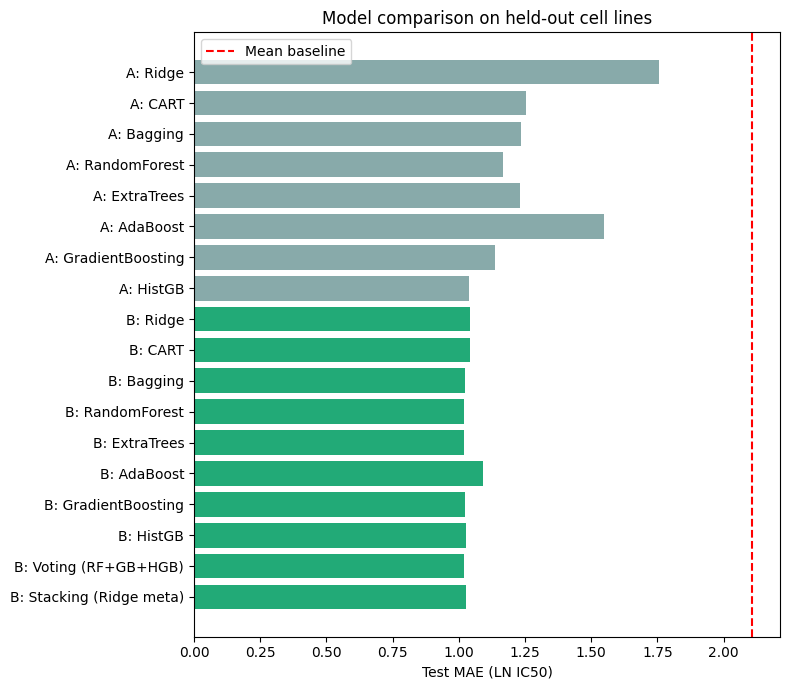

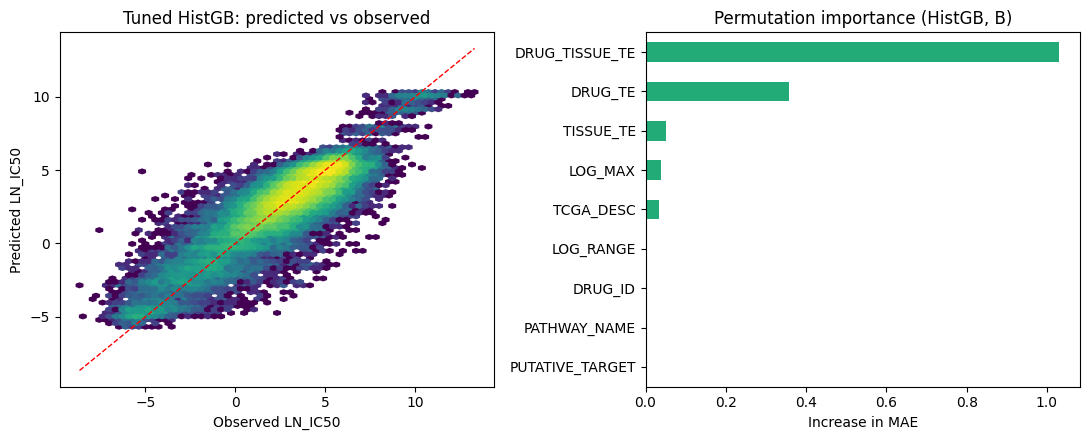

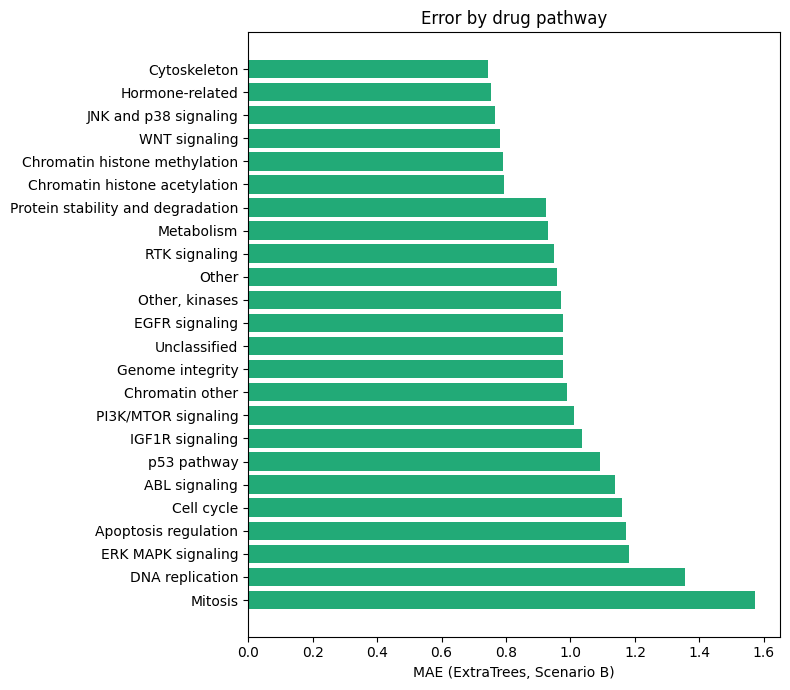

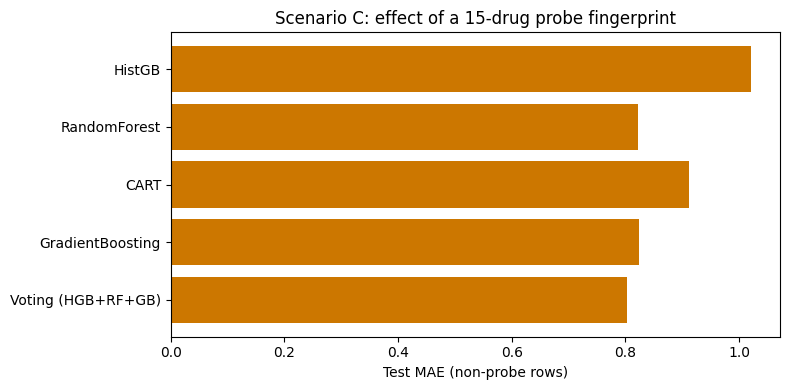

In [36]:
# 12.15 Figures
b = results[results["Scenario"].isin(["A", "B"])].copy()
b["label"] = b["Scenario"] + ": " + b["Model"]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(b["label"], b["MAE"], color=["#8aa" if s == "A" else "#2a7" for s in b["Scenario"]])
ax.axvline(results.loc[results["Model"] == "Mean baseline", "MAE"].iloc[0], color="r", ls="--", label="Mean baseline")
ax.set_xlabel("Test MAE (LN IC50)"); ax.set_title("Model comparison on held-out cell lines"); ax.legend(); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("fig_pbl3_model_comparison.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hexbin(y_test, preds[("B", "HistGB_tuned")], gridsize=60, bins="log", cmap="viridis")
lo, hi = float(y_test.min()), float(y_test.max())
axes[0].plot([lo, hi], [lo, hi], "r--", lw=1)
axes[0].set_xlabel("Observed LN_IC50"); axes[0].set_ylabel("Predicted LN_IC50"); axes[0].set_title("Tuned HistGB: predicted vs observed")
imp.sort_values().plot.barh(ax=axes[1], color="#2a7"); axes[1].set_xlabel("Increase in MAE"); axes[1].set_title("Permutation importance (HistGB, B)")
plt.tight_layout(); plt.savefig("fig_pbl3_pred_importance.png", dpi=200); plt.show()

pm = path_mae.sort_values("MAE")
plt.figure(figsize=(8, 7)); plt.barh(pm.index, pm["MAE"], color="#2a7"); plt.xlabel("MAE (ExtraTrees, Scenario B)")
plt.title("Error by drug pathway"); plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig("fig_pbl3_pathway_mae.png", dpi=200); plt.show()

allC = pd.concat([resultsC], ignore_index=True)
plt.figure(figsize=(8, 4)); plt.barh(allC["Model"], allC["MAE"], color="#c70"); plt.gca().invert_yaxis()
plt.xlabel("Test MAE (non-probe rows)"); plt.title("Scenario C: effect of a 15-drug probe fingerprint")
plt.tight_layout(); plt.savefig("fig_pbl3_scenario_C.png", dpi=200); plt.show()

### 12.16 Reading the PBL-III results
- **Ensembles help most where the inputs are weak.** In Scenario A, bagging, random forests and boosting clearly beat a single CART tree and the linear baseline.
- **Once target encodings are added (Scenario B), almost every model converges** (test MAE near 1.02-1.04). The bootstrap shows that the remaining gaps between the best ensembles are statistical ties, so the simplest fast model is a sensible production choice.
- **The encodings do most of the work.** Permutation importance is dominated by `DRUG_TISSUE_TE` and `DRUG_TE`: Scenario B is largely a drug-by-tissue average, with no per-cell-line information because the file has no omics columns.
- **Per-cell-line information appears only in Scenario C**, where measured responses to 15 probe drugs act as a fingerprint. That needs 15 extra assays on any new cell line.
- Classification accuracy and AUC are a thresholded view of the same regression predictions, not a separate model.
- These are cell-line results; they are not evidence of clinical benefit.

---
# 13. Production Packaging

The production candidate is the tuned HistGB on Scenario B features. After model selection and the untouched grouped hold-out evaluation in Section 12, this section refits a fresh Scenario B featurizer and HistGB model on **all 242,036 available rows from 969 cell lines** using the selected hyperparameters. The held-out metrics reported in the model card remain the independent evaluation results from the earlier split; they are not recomputed on the refit data.

This section saves the full-data model, featurizer, encoders and lookup tables, writes a model card, and provides a validated `predict_response` function with tests.

Inputs at inference: a **drug** (`DRUG_ID` or unique drug name) and a **tissue** (`TCGA_DESC`). The output is a cell-line-level LN(IC50) estimate for that drug in that tissue type. It is **not** a prediction for an individual patient.

The production featurizer creates grouped out-of-fold target encodings for rows used to fit the model, while retaining target-encoding statistics fitted on all available training rows for future inference. The hold-out test set is not used to select or report new performance metrics after refitting.


In [37]:
# 13.1 Refit on ALL available data, then save the production bundle and model card
import joblib, shutil
ART = "oncomatch_artifacts"
os.makedirs(ART, exist_ok=True)

# Keep the untouched hold-out evaluation above as the reported performance estimate.
# Refit a NEW featurizer and model on all rows only after model selection/evaluation.
production_featurizer = DrugResponseFeaturizer(K_SMOOTH, 5)
X_full_B = production_featurizer.fit_transform(g, groups=g["COSMIC_ID"])
y_full = g[TARGET].to_numpy()

production_model = HistGradientBoostingRegressor(random_state=SEED, **best_params)
production_model.fit(X_full_B, y_full)

# Save the full-data inference bundle (not the train-split model).
bundle = {
    "featurizer": production_featurizer,
    "model": production_model,
    "feature_columns": production_featurizer.columns_,
    "training_rows": int(len(g)),
    "training_cell_lines": int(g["COSMIC_ID"].nunique()),
    "training_scope": "All available GDSC2 rows; grouped OOF target encodings",
}
joblib.dump(bundle, f"{ART}/oncomatch_pbl3_bundle.joblib", compress=3)
shutil.copy("oncomatch_features.py", f"{ART}/oncomatch_features.py")

drug_catalog = (g.groupby("DRUG_ID").agg(
    DRUG_NAME=("DRUG_NAME", "first"),
    PUTATIVE_TARGET=("PUTATIVE_TARGET", "first"),
    PATHWAY_NAME=("PATHWAY_NAME", "first"),
    MIN_CONC=("MIN_CONC", lambda s: s.mode().iloc[0]),
    MAX_CONC=("MAX_CONC", lambda s: s.mode().iloc[0])
).reset_index())
drug_catalog.to_csv(f"{ART}/drug_catalog.csv", index=False)

tissues = sorted(g["TCGA_DESC"].fillna("UNKNOWN").unique().tolist())
resid = y_test - p_tuned
tm = scores(y_test, p_tuned)
card = {
    "name": "OncoMatch PBL-III drug-response regressor",
    "model": "HistGradientBoostingRegressor (tuned; refitted on all available data)",
    "target": "LN_IC50 (GDSC2 fitted)",
    "intended_use": "Course project: exploratory estimate of ln(IC50) for a drug in a cancer tissue type",
    "not_for": "Clinical decisions or patient treatment selection",
    "data": {
        "source": "GDSC2_fitted_dose_response_24Jul22.csv",
        "rows": int(len(g)),
        "cell_lines": int(g["COSMIC_ID"].nunique()),
        "drug_names": int(g["DRUG_NAME"].nunique()),
        "tissue_labels": len(tissues)
    },
    "evaluation": {
        "method": "Cell-line-grouped 80:20 hold-out (seed 42); test cell lines unseen during model selection",
        "train_rows": int(len(train)),
        "test_rows": int(len(test)),
        "train_cell_lines": int(train["COSMIC_ID"].nunique()),
        "test_cell_lines": int(test["COSMIC_ID"].nunique()),
        "test_metrics": {k: round(float(v), 4) for k, v in tm.items()},
        "mean_baseline_test_MAE": round(float(results.loc[results["Model"] == "Mean baseline", "MAE"].iloc[0]), 4)
    },
    "production_refit": {
        "rows": int(len(g)),
        "cell_lines": int(g["COSMIC_ID"].nunique()),
        "feature_strategy": "Scenario B; grouped out-of-fold target encodings for model-fitting rows",
        "hyperparameters_selected_on": "Training split only, using grouped cross-validation"
    },
    "residual_band_80pct_on_holdout": [
        round(float(np.percentile(resid, 10)), 3),
        round(float(np.percentile(resid, 90)), 3)
    ],
    "inputs": ["DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME", "TCGA_DESC", "MIN_CONC", "MAX_CONC"],
    "excluded_inputs": sorted(FORBIDDEN_INPUTS),
    "limitations": [
        "No omics columns: cannot separate cell lines of the same tissue",
        "Cell-line data does not establish clinical effectiveness",
        "Predictions for unseen drugs are not validated",
        "UNCLASSIFIED is the largest tissue group"
    ],
    "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.items()}
}
with open(f"{ART}/model_card.json", "w") as f:
    json.dump(card, f, indent=2)

json.dump({
    "tissues": tissues,
    "train_median_ln_ic50": train_median,
    "training_rows": int(len(g)),
    "training_cell_lines": int(g["COSMIC_ID"].nunique())
}, open(f"{ART}/meta.json", "w"), indent=2)

print("Independent hold-out metrics:", json.dumps(card["evaluation"]["test_metrics"], indent=2))
print("Production refit:", bundle["training_rows"], "rows /", bundle["training_cell_lines"], "cell lines")
print("Saved:", sorted(os.listdir(ART)))


Independent hold-out metrics: {
  "MAE": 1.027,
  "RMSE": 1.3612,
  "R2": 0.7585
}
Production refit: 242036 rows / 969 cell lines
Saved: ['drug_catalog.csv', 'meta.json', 'model_card.json', 'oncomatch_features.py', 'oncomatch_pbl3_bundle.joblib']


In [38]:
# 13.2 Validated inference function
_meta = json.load(open(f"{ART}/meta.json"))
_cat = pd.read_csv(f"{ART}/drug_catalog.csv")
NEED = ["DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME", "TCGA_DESC", "MIN_CONC", "MAX_CONC"]

def build_query(drug, tissue):
    """Build one model-ready row from a known drug ID/name and tissue label."""
    if tissue not in _meta["tissues"]:
        raise ValueError(f"Unknown tissue '{tissue}'. Valid values: {_meta['tissues']}")
    if isinstance(drug, (int, np.integer)) or str(drug).strip().isdigit():
        r = _cat[_cat["DRUG_ID"] == int(drug)]
    else:
        r = _cat[_cat["DRUG_NAME"].str.lower() == str(drug).strip().lower()]
    if r.empty:
        raise ValueError(f"Unknown drug '{drug}'.")
    if len(r) > 1:
        raise ValueError(f"'{drug}' maps to several DRUG_IDs {r['DRUG_ID'].tolist()}; pass a DRUG_ID.")
    q = r.iloc[0][NEED[:3] + NEED[4:]].to_frame().T
    q["TCGA_DESC"] = tissue
    return q[NEED].astype({"MIN_CONC": float, "MAX_CONC": float})

def predict_response(rows, bundle_path=f"{ART}/oncomatch_pbl3_bundle.joblib"):
    """Predict cell-line-level LN_IC50; lower values indicate greater in-vitro sensitivity."""
    miss = [c for c in NEED if c not in rows.columns]
    if miss:
        raise ValueError(f"Missing required columns: {miss}")
    out = rows[NEED].copy()
    numeric = out[["MIN_CONC", "MAX_CONC"]].apply(pd.to_numeric, errors="coerce")
    if not np.isfinite(numeric.to_numpy()).all():
        raise ValueError("MIN_CONC and MAX_CONC must be finite numeric values")
    if (numeric <= 0).any().any():
        raise ValueError("MIN_CONC and MAX_CONC must be positive")
    if (numeric["MIN_CONC"] > numeric["MAX_CONC"]).any():
        raise ValueError("MIN_CONC cannot exceed MAX_CONC")
    out[["MIN_CONC", "MAX_CONC"]] = numeric
    if out[["DRUG_ID", "PUTATIVE_TARGET", "PATHWAY_NAME", "TCGA_DESC"]].isna().any().any():
        raise ValueError("Drug and tissue feature fields cannot be missing")
    b = joblib.load(bundle_path)
    if list(b["feature_columns"]) != list(b["featurizer"].columns_):
        raise ValueError("Saved bundle feature schema is inconsistent")
    out["PRED_LN_IC50"] = b["model"].predict(b["featurizer"].transform(out[NEED]))
    return out

q = build_query(int(_cat["DRUG_ID"].iloc[0]), _meta["tissues"][0])
display(predict_response(q))
demo = test.head(3)[NEED]
display(predict_response(demo).assign(ACTUAL=test.head(3)["LN_IC50"].values))


,DRUG_ID,PUTATIVE_TARGET,PATHWAY_NAME,TCGA_DESC,MIN_CONC,MAX_CONC,PRED_LN_IC50
0,1003,TOP1,DNA replication,ACC,0.0001,0.1,-3.081726


,DRUG_ID,PUTATIVE_TARGET,PATHWAY_NAME,TCGA_DESC,MIN_CONC,MAX_CONC,PRED_LN_IC50,ACTUAL
0,1003,TOP1,DNA replication,UNCLASSIFIED,0.0001,0.1,-2.840589,0.535367
1,1003,TOP1,DNA replication,LUAD,0.0001,0.1,-1.854173,0.137554
2,1003,TOP1,DNA replication,LUAD,0.0001,0.1,-1.854173,0.129242


In [39]:
# 13.3 Automated sanity tests
def _raises(fn, *a):
    try:
        fn(*a)
    except ValueError:
        return True
    return False

assert len(set(train["COSMIC_ID"]) & set(test["COSMIC_ID"])) == 0
assert not set(FORBIDDEN_INPUTS) & set(production_featurizer.columns_)
assert production_featurizer is not fb
assert len(g) == 242036 and g["COSMIC_ID"].nunique() == 969
assert _meta["training_rows"] == len(g)
assert _meta["training_cell_lines"] == g["COSMIC_ID"].nunique()
assert _raises(build_query, "NotADrug", _meta["tissues"][0])
assert _raises(build_query, int(_cat["DRUG_ID"].iloc[0]), "NOT_A_TISSUE")
assert _raises(predict_response, demo.drop(columns=["TCGA_DESC"]))
assert _raises(predict_response, demo.assign(MAX_CONC=-1.0))
assert _raises(predict_response, demo.assign(MIN_CONC=10.0, MAX_CONC=1.0))
assert _raises(predict_response, demo.assign(MAX_CONC=np.nan))

# Repeated calls through the saved full-data bundle must be deterministic.
a1 = predict_response(demo)["PRED_LN_IC50"].values
a2 = predict_response(demo)["PRED_LN_IC50"].values
assert np.allclose(a1, a2), "Saved-bundle predictions must be deterministic"
assert np.isfinite(a1).all()
assert np.isfinite(predict_response(q)["PRED_LN_IC50"]).all()

# The held-out model's score is still evaluated only on the untouched test set.
assert scores(y_test, p_tuned)["MAE"] < scores(
    y_test, np.full_like(y_test, y_train.mean())
)["MAE"]
unseen = demo.copy()
unseen["DRUG_ID"] = -999
assert np.isfinite(predict_response(unseen)["PRED_LN_IC50"]).all()
print("All production-bundle and hold-out sanity tests passed.")


All production-bundle and hold-out sanity tests passed.


In [40]:
# 13.4 Persist evaluation metrics separately from the full-data production refit
tuned_row = [r for r in rows if r["Model"] == "HistGB (tuned)"][0]
metrics = {
    "evaluation_split": "GroupShuffleSplit by COSMIC_ID, 80:20, seed 42",
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "train_cell_lines": int(train["COSMIC_ID"].nunique()),
    "test_cell_lines": int(test["COSMIC_ID"].nunique()),
    "mean_baseline_test_MAE": float(results.loc[results["Model"] == "Mean baseline", "MAE"].iloc[0]),
    "tuned_histgb_holdout": {k: round(float(tuned_row[k]), 4) for k in ["MAE", "RMSE", "R2"]},
    "production_refit_rows": int(len(g)),
    "production_refit_cell_lines": int(g["COSMIC_ID"].nunique()),
    "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in best_params.items()},
    "classification_view_threshold": train_median
}
json.dump(metrics, open(f"{ART}/metrics.json", "w"), indent=2)

card_text = f"""# OncoMatch model card

**Model:** HistGradientBoostingRegressor on Scenario B features, refitted on all available GDSC2 rows after model selection.

**Task:** estimate LN(IC50) for a drug in a tissue type from GDSC2 cell-line screens.

**Data:** GDSC2 fitted dose response (24Jul22): {len(g):,} rows, {g['COSMIC_ID'].nunique()} cell lines, {g['DRUG_NAME'].nunique()} drug names, {len(tissues)} tissue labels. No omics columns.

**Independent evaluation:** cell-line-grouped 80:20 hold-out, seed 42. Tuned HistGB test MAE {metrics['tuned_histgb_holdout']['MAE']}, RMSE {metrics['tuned_histgb_holdout']['RMSE']}, R2 {metrics['tuned_histgb_holdout']['R2']}; mean-baseline test MAE {metrics['mean_baseline_test_MAE']:.3f}.

**Production fit:** final featurizer and model refitted on all {len(g):,} rows from {g['COSMIC_ID'].nunique()} cell lines. Training rows use grouped out-of-fold target encodings; inference uses target-encoding statistics learned from all available training rows.

**Not used as inputs:** AUC, Z_SCORE, RMSE (same curve fit as the target).

**Intended use:** education and research demonstration of ensemble learning on public cell-line data.

**Out of scope:** clinical decisions, patient-level prediction, treatment recommendation.

**Known limitations:** (1) the model is mostly a drug-by-tissue average, with no per-cell-line molecular information; (2) cell-line responses are not clinical outcomes; (3) accuracy varies by pathway (see Section 12.13); (4) predictions for unseen drugs are not validated.
"""
open(f"{ART}/MODEL_CARD.md", "w").write(card_text)
print(card_text)


# OncoMatch model card

**Model:** HistGradientBoostingRegressor on Scenario B features, refitted on all available GDSC2 rows after model selection.

**Task:** estimate LN(IC50) for a drug in a tissue type from GDSC2 cell-line screens.

**Data:** GDSC2 fitted dose response (24Jul22): 242,036 rows, 969 cell lines, 286 drug names, 33 tissue labels. No omics columns.

**Independent evaluation:** cell-line-grouped 80:20 hold-out, seed 42. Tuned HistGB test MAE 1.027, RMSE 1.3612, R2 0.7585; mean-baseline test MAE 2.108.

**Production fit:** final featurizer and model refitted on all 242,036 rows from 969 cell lines. Training rows use grouped out-of-fold target encodings; inference uses target-encoding statistics learned from all available training rows.

**Not used as inputs:** AUC, Z_SCORE, RMSE (same curve fit as the target).

**Intended use:** education and research demonstration of ensemble learning on public cell-line data.

**Out of scope:** clinical decisions, patient-level predicti

---
# 14. Final Summary

| PBL | Unit | Technique | What it shows | How to read the numbers |
|---|---|---|---|---|
| I | 1-2 | Regression and classification (Linear, Ridge, Random Forest, Logistic, SVM) | baseline predictability of LN(IC50) | inputs were curve summaries (`AUC`, `Z_SCORE`, `RMSE`), so results are **leakage-affected** and exploratory only |
| II | 3 | K-Means (k = 2) | two groups of response records (168,604 / 73,432), silhouette 0.4149 | internal cluster metric only |
| II | 4 | Categorical HMM (3 states) | method demonstration on DRUG_ID-ordered sequences, log-likelihood -254,147.60 | transitions are **not** biological progression |
| III | 5 | CART, bagging, boosting, voting, stacking | ensembles vs a single tree on unseen cell lines | compare only inside Section 12 |

**PBL-III results (test set: 194 unseen cell lines, 48,445 rows).**
- Mean baseline MAE 2.108. Scenario A: CART 1.255 vs HistGB 1.040. Scenario B: all models near MAE 1.02-1.04, best ExtraTrees 1.021.
- Tuned HistGB (chosen for production): test MAE 1.029, RMSE 1.365, R2 0.757.
- Cell-line bootstrap: CART minus ExtraTrees MAE = 0.023 (95% CI 0.018 to 0.029); ExtraTrees minus Voting is a tie (CI includes 0).
- Scenario C (15 probe drugs measured on the cell line): MAE 1.025 to 0.790 for HistGB on the same rows (R2 0.748 to 0.851).

**Production note:** After the grouped hold-out evaluation, the final HistGB and Scenario B featurizer are refitted on all 242,036 rows / 969 cell lines for inference. The hold-out metrics above remain the evaluation results; they are not training-set scores.\n\n**Take-aways.**
1. Ensembles clearly beat a single tree on raw categories, but converge once drug and tissue target encodings are supplied.
2. The drug-and-tissue-only ceiling (R2 about 0.76) is the limit: there are no omics columns in the file. Per-cell-line information (probe assays) is what lowers the error further.
3. Nothing here supports patient-level treatment recommendations. Cell-line results need independent validation with omics and external data before any clinical interpretation.
